**Estimated time:** ~45 minutes
**Depends on:** Annotation and Classification with JABS
**Unlocks:** Future independent work - applying this workflow to your own data

Behavior classification produces labels. This notebook turns those labels into understanding: when does grooming occur, how long do bouts last, how well does the classifier match expert annotations, and what does pose look like during labeled grooming frames.

We use the pre-computed JABS grooming project - reference annotations and classifier predictions for a set of 5-minute single-mouse open-field clips. If you ran Annotation and Classification with JABS and produced your own predictions, set `my_predictions_dir` in the parameters cell.


## Learning Goals

By the end of this page, you should be able to:

- Turn raw behavior annotations into an ethogram and a bout-duration distribution
- Explain the "null model trap" - why a naive majority-class baseline can look deceptively good
- Evaluate a trained classifier's predictions against ground truth using metrics that account for class imbalance, not just accuracy
- Connect classifier output back to the underlying pose and movement data to sanity-check what the model actually learned


## The Data

This page uses the same **JABS grooming example project** introduced in [Data Ingestion](01_data_ingestion.html) - see that page for the dataset citation, license, and session structure.

What is new here: annotation files record grooming bout intervals using `unfragmented_labels`, a complete partition of reviewed frames into `present` (grooming) and `not present` (confirmed non-grooming) bouts. Sessions where (almost) every frame was reviewed form the **dense test set** used for unbiased metrics below.


In [1]:
# Why: knobs papermill/CI (or you, with your own predictions) can override
# without editing the notebook body.
# --- parameters ---
data_subdir        = ""   # "" = auto-detect (zenodo -> toy fallback)
my_predictions_dir = ""   # "" = use pre-computed dense-GT predictions
                          # set to your own Annotation and Classification
                          # with JABS output, e.g.:
                          # str(project_root / "data" / "predictions" / "grooming")
BEHAVIOR = "grooming"
classifier_path = ""    # "" = the classifier trained in the live walkthrough
                          # (data/zenodo_scrubbed/jabs_grooming/jabs/classifiers/grooming_livedemo.pkl)

In [2]:
# Why: import everything this page needs, then locate the repo root and
# pick which data tier this page reads from.
import json
import os
import subprocess
import sys
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from jabs.core.abstract.pose_est import PoseEstimation

# Locate the project root - a straight walk-up from the working directory
# looking for requirements.txt + student_notebooks/. This page is built once
# via papermill from the repo root, so that is the only path that matters.
current = Path.cwd().resolve()
for _ in range(10):
    if (current / "requirements.txt").exists() and (current / "student_notebooks").is_dir():
        project_root = current
        break
    current = current.parent
else:
    raise RuntimeError(
        "Could not find project root. Run this notebook from within the repo."
    )

# --- two-tier data detection ---
_zenodo = project_root / 'data' / 'zenodo' / 'jabs_grooming'
if data_subdir:
    data_dir = project_root / 'data' / data_subdir
elif list(_zenodo.glob('*_pose_est_v6.h5')):
    data_dir = _zenodo
else:
    data_dir = project_root / 'data' / 'toy'

ann_dir    = data_dir / 'jabs' / 'annotations'
# One session (2010) has a hand-reviewed, fully-dense ground-truth
# annotation that lives outside the regular data/ tiers - see
# student_scripts/make_scrubbed_practice_set.py for why. Loaded below
# in place of whatever partial annotation that session ships with.
dense_gt_dir = project_root / 'data' / 'dense_gt_a1'
pose_files = sorted(data_dir.glob('*_pose_est_v6.h5'))
session_ids = [p.stem.split('_pose_est')[0] for p in pose_files]

print(f'Data directory : {data_dir}')
print(f'Sessions found : {len(session_ids)}')
print(f'Annotation dir : {ann_dir}  exists={ann_dir.exists()}')

KEYPOINT_NAMES = [k.name.lower() for k in PoseEstimation.KeypointIndex]

# Colors and plot helpers shared with the live walkthrough: orange = behavior,
# blue = not behavior, light gray = not reviewed (as in the JABS GUI).
import numpy as np
from matplotlib.patches import Patch

BEHAVIOR_COLOR = "#FFA500"      # behavior present (orange, as in the JABS GUI)
NOT_BEHAVIOR_COLOR = "#0056E5"  # not the behavior (blue, as in the JABS GUI)
UNREVIEWED_COLOR = "#D9D9D9"    # no label / not reviewed
DISAGREE_COLOR = "#222222"      # frames where two annotators disagree
METRIC_COLORS = {"Accuracy": "#6B6B6B", "Recall": "#009E73", "Precision": "#7B3294", "F1": "#B2182B"}


def _runs(mask):
    """Find the runs of True in a boolean array.

    Args:
        mask: A 1-D boolean array.

    Returns:
        A list of (start, length) pairs, one per run of True, in frame order.
    """
    padded = np.concatenate([[False], np.asarray(mask, dtype=bool), [False]])
    change = np.flatnonzero(padded[1:] != padded[:-1])
    return list(zip(change[::2], change[1::2] - change[::2]))


def ethogram(rows, title=None, width=12, row_height=0.5):
    """Draw an ethogram with one facet (row) per video, annotator or stage.

    Args:
        rows: A list of (label, frames) pairs, or (label, frames, "disagree") for a
            row that marks disagreement. frames is a per-frame array: -1 not reviewed,
            0 not behavior, 1 behavior.
        title: Optional figure title.
        width: Figure width in inches.
        row_height: Height of each row in inches.

    Returns:
        The matplotlib figure.
    """
    n_frames = max(len(r[1]) for r in rows)
    fig, axes = plt.subplots(
        len(rows), 1, sharex=True, squeeze=False, figsize=(width, row_height * len(rows) + 0.9)
    )
    for ax, row in zip(axes[:, 0], rows):
        label, frames = row[0], np.asarray(row[1])
        if len(row) > 2 and row[2] == "disagree":
            ax.broken_barh(_runs(frames == 1), (0, 1), facecolors=DISAGREE_COLOR)
        else:
            ax.broken_barh([(0, len(frames))], (0, 1), facecolors=UNREVIEWED_COLOR)
            ax.broken_barh(_runs(frames == 0), (0, 1), facecolors=NOT_BEHAVIOR_COLOR)
            ax.broken_barh(_runs(frames == 1), (0, 1), facecolors=BEHAVIOR_COLOR)
        ax.set_xlim(0, n_frames)
        ax.set_ylim(0, 1)
        ax.set_yticks([])
        ax.set_ylabel(label, rotation=0, ha="right", va="center", fontsize=9)
        for spine in ax.spines.values():
            spine.set_visible(False)
    axes[-1, 0].set_xlabel("Frame (30 frames = 1 second)")
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    return fig


def metric_bars(ax, stages, title=None):
    """Draw accuracy, recall, precision and F1 bars, one color per metric.

    Args:
        ax: The matplotlib axes to draw on.
        stages: A dict of stage label to {metric name: value}, in the order they
            should appear. All but the last stage are drawn lighter.
        title: Optional axes title.
    """
    names = list(METRIC_COLORS)
    width = 0.8 / len(stages)
    for k, (stage_label, values) in enumerate(stages.items()):
        alpha = 1.0 if k == len(stages) - 1 else 0.45
        xs = np.arange(len(names)) + (k - (len(stages) - 1) / 2) * width
        bars = ax.bar(xs, [values[n] for n in names], width, color=[METRIC_COLORS[n] for n in names], alpha=alpha)
        for bar, name in zip(bars, names):
            ax.text(bar.get_x() + bar.get_width() / 2, values[name] + 0.02, f"{values[name]:.2f}",
                    ha="center", va="bottom", fontsize=8)
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels(names)
    ax.set_ylim(0, 1.12)
    ax.set_ylabel("Score")
    if title:
        ax.set_title(title)
    if len(stages) > 1:
        shades = [("#6B6B6B", 1.0 if k == len(stages) - 1 else 0.45) for k in range(len(stages))]
        ax.legend(handles=[Patch(facecolor=c, alpha=a, label=lab) for (c, a), lab in zip(shades, stages)],
                  loc="lower right", fontsize=8)


os.environ["PYTHONIOENCODING"] = "utf-8"  # the JABS commands print Unicode spinners


def jabs_exe(name):
    """Find a JABS console script, preferring the one beside this Python.

    Args:
        name: Console script name, for example "jabs-cli".

    Returns:
        The full path if it exists beside the interpreter, otherwise the bare name.
    """
    exe_dir = Path(sys.executable).parent
    for candidate in (exe_dir / name, exe_dir / f"{name}.exe", exe_dir / "Scripts" / f"{name}.exe"):
        if candidate.exists():
            return str(candidate)
    return name


def clean_output(text):
    """Drop the progress-spinner lines JABS tools print, keeping everything else.

    Args:
        text: Captured stdout or stderr of a JABS command.

    Returns:
        The text without spinner lines or blank lines.
    """
    keep = [ln for ln in (text or "").splitlines()
            if ln.strip() and not any("\u2800" <= ch <= "\u28ff" for ch in ln)]
    return "\n".join(keep)

Data directory : getting-started-with-jabs\data\zenodo\jabs_grooming
Sessions found : 25
Annotation dir : getting-started-with-jabs\data\zenodo\jabs_grooming\jabs\annotations  exists=True


## Load Annotations

Each annotation file uses `unfragmented_labels`: a complete partition of reviewed frames into bouts tagged `present` (grooming) or not. We build two structures:

1. A **bout table** (one row per grooming interval) for ethograms and duration analysis.
2. A **per-frame label array** (`1` = grooming, `0` = not-grooming, `-1` = unreviewed) for metric computation.


In [3]:
# Why: turn each session's raw annotation JSON into two things every later
# cell needs - a bout table (for ethograms) and a per-frame label array
# (for metric computation).
bouts = []
frame_labels = {}

for pose_path in pose_files:
    sid = pose_path.stem.split('_pose_est')[0]
    # Use the dense-GT annotation for this session if one exists, instead
    # of the (partial) annotation that ships in the regular data tier.
    dense_override = dense_gt_dir / 'jabs' / 'annotations' / f'{sid}.json'
    ann_path = dense_override if dense_override.exists() else ann_dir / f'{sid}.json'

    with h5py.File(str(pose_path), 'r') as f:
        n_frames = f['poseest/points'].shape[0]

    labels = np.full(n_frames, -1, dtype=np.int8)

    if ann_path.exists():
        d = json.loads(ann_path.read_text(encoding='utf-8'))
        # unfragmented_labels is keyed by identity, then by behavior name,
        # then a list of {start, end, present} bout intervals - present=True
        # bouts both set the per-frame label and get their own bout row.
        for identity, behaviors in d.get('unfragmented_labels', {}).items():
            for behavior, intervals in behaviors.items():
                if behavior.lower() != BEHAVIOR:
                    continue
                for iv in intervals:
                    start, end = int(iv['start']), int(iv['end'])
                    val = 1 if iv.get('present', False) else 0
                    labels[start:end] = val
                    if iv.get('present', False):
                        bouts.append({
                            'session': sid,
                            'start': start,
                            'end': end,
                            'length': end - start,
                        })

    frame_labels[sid] = labels

bouts_df = pd.DataFrame(bouts) if bouts else pd.DataFrame(
    columns=['session', 'start', 'end', 'length']
)
print(f'Loaded {len(session_ids)} sessions, {len(bouts_df)} grooming bouts total')


Loaded 25 sessions, 18 grooming bouts total


## Annotation Coverage

Only sessions with **complete coverage** (all frames labeled) are suitable as the dense test set. Partial sessions introduce bias: unlabeled grooming frames count as false negatives even though the annotator never reviewed them.


In [4]:
# Why: decide which sessions are fully enough reviewed to serve as the dense
# test set, since partial labels would bias the metrics.
# A session rarely reaches literally 100% coverage (an annotator may skip
# a handful of ambiguous frames even on a otherwise fully-reviewed pass),
# so treat 99%+ reviewed as "dense" rather than requiring an exact 100%.
DENSE_COVERAGE_THRESHOLD = 0.99

rows = []
for pose_path in pose_files:
    sid = pose_path.stem.split('_pose_est')[0]
    with h5py.File(str(pose_path), 'r') as f:
        n_frames = f['poseest/points'].shape[0]
    reviewed = int((frame_labels[sid] >= 0).sum())
    grooming = int((frame_labels[sid] == 1).sum())
    rows.append({
        'session':        sid,
        'session_frames': n_frames,
        'reviewed':       reviewed,
        'coverage_pct':   100 * reviewed / n_frames,
        'grooming_frames':grooming,
        'grooming_pct':   100 * grooming / max(reviewed, 1),
        'dense':          reviewed >= DENSE_COVERAGE_THRESHOLD * n_frames,
    })

coverage_df = pd.DataFrame(rows)
print(coverage_df.to_string(index=False, float_format=lambda x: f'{x:.1f}'))

dense_sessions = coverage_df.loc[coverage_df['dense'], 'session'].tolist()
print(f'\nDensely annotated sessions ({len(dense_sessions)}): {dense_sessions}')
print('Only dense sessions are valid for unbiased metric computation.')


session  session_frames  reviewed  coverage_pct  grooming_frames  grooming_pct  dense
   2001            2469      2378          96.3             2090          87.9  False
   2002            2298         0           0.0                0           0.0  False
   2003            2636         0           0.0                0           0.0  False
   2004             996         0           0.0                0           0.0  False
   2005            1548         0           0.0                0           0.0  False
   2006            3421         0           0.0                0           0.0  False
   2007           10788      6937          64.3              376           5.4  False
   2008             614         0           0.0                0           0.0  False
   2009             912       835          91.6              534          64.0  False
   2010            1491      1478          99.1              782          52.9   True
   2011            5664         0           0.0       

## Ethogram: When Does Grooming Occur?

Each row is a session; each bar is a grooming bout. This gives a quick visual sense of how much grooming occurs, whether bouts cluster early or late in the clip, and whether some sessions are unusually sparse or dense.


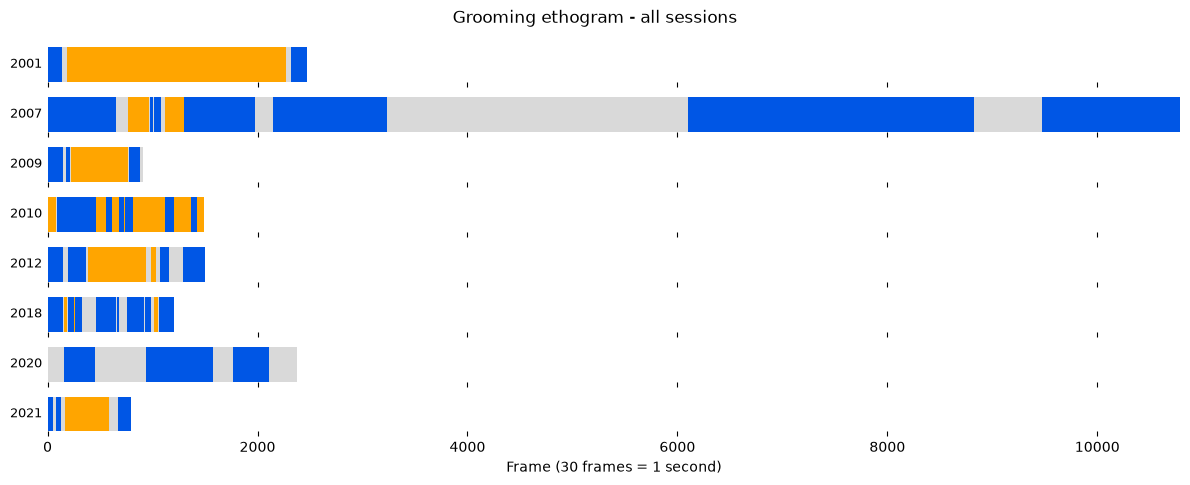

In [5]:
# Why: show every session's labels on one timeline, one row per session, to see how
# much grooming occurs and whether it clusters or spreads out. Orange = grooming,
# blue = not grooming, gray = not reviewed.
rows = [(sid, frame_labels[sid]) for sid in sorted(frame_labels) if (frame_labels[sid] >= 0).any()]
if not rows:
    print('No labels found - check annotation path.')
else:
    ethogram(rows, title='Grooming ethogram - all sessions')
    plt.show()

## Bout Duration Distribution

How long are grooming bouts? The distribution is typically right-skewed: many short bouts (brief face-wipes), a tail of sustained grooming sequences.


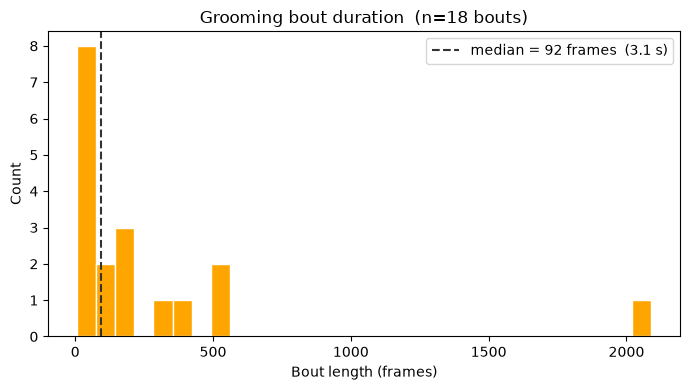

In [6]:
# Why: see whether grooming bouts are mostly brief face-wipes, sustained
# sequences, or a mix - the shape of this distribution matters for later
# feature choices.
if bouts_df.empty:
    print('No bouts to plot.')
else:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(bouts_df['length'], bins=30, color=BEHAVIOR_COLOR, edgecolor='white')
    ax.set_xlabel('Bout length (frames)')
    ax.set_ylabel('Count')
    median_len = bouts_df['length'].median()
    ax.axvline(median_len, color='#333333', linewidth=1.5, linestyle='--',
               label=f'median = {median_len:.0f} frames  ({median_len/30:.1f} s)')
    ax.set_title(f'Grooming bout duration  (n={len(bouts_df)} bouts)')
    ax.legend()
    plt.tight_layout()
    plt.show()

## Score the Classifier With JABS

Every performance number on this page comes from the JABS command line. `jabs-cli evaluate` runs a trained classifier over the dense ground-truth project (`data/dense_gt_a1/`, session 2010, never used for training) and compares its predictions with the labels, frame by frame and bout by bout. We use the classifier you trained in the live walkthrough; set `classifier_path` above to use a different one.

In [7]:
# Why: score the classifier on the dense ground-truth project with JABS's own evaluate
# command, so the metrics below are the ones JABS reports, not our own arithmetic.
_default_classifier = (project_root / 'data' / 'zenodo_scrubbed' / 'jabs_grooming' / 'jabs'
                       / 'classifiers' / f'{BEHAVIOR}_livedemo.pkl')
clf_path = Path(classifier_path) if classifier_path else _default_classifier
# Results go next to the classifier, outside the shipped data folders.
eval_out = clf_path.parent.parent / 'evaluation_nb05'
eval_json = None

if not clf_path.exists():
    print(f'[MISSING] No trained classifier at {clf_path}')
    print('  Run the live walkthrough through its Train and Classify step first, or set classifier_path above.')
else:
    eval_out.mkdir(parents=True, exist_ok=True)
    for old_file in eval_out.rglob('*'):
        if old_file.is_file():
            old_file.unlink()
    result = subprocess.run(
        [jabs_exe('jabs-cli'), 'evaluate', str(dense_gt_dir), '--classifier', str(clf_path),
         '--behavior', BEHAVIOR, '--save-predictions', str(eval_out / 'predictions'), '--out-dir', str(eval_out)],
        capture_output=True, text=True, encoding='utf-8', errors='replace',
    )
    summaries = sorted(eval_out.glob('*_evaluation.json'))
    if result.returncode != 0 or not summaries:
        print('Evaluation failed:')
        print(clean_output(result.stderr or result.stdout))
    else:
        eval_json = json.loads(summaries[-1].read_text(encoding='utf-8'))
        print(f'Evaluated {dense_gt_dir.name} with {clf_path.name}')

Evaluated dense_gt_a1 with grooming_livedemo.pkl


## Load Classifier Predictions

Predictions are per-frame binary labels produced by [`jabs-classify classify`](https://kumarlabjax.github.io/JABS-behavior-classifier/user-guide/cli-tools/) - "classify a pose file," per the JABS documentation. We load pre-computed predictions from `data/toy/predictions/grooming/` unless you have set `my_predictions_dir` to your own NB04 output.

Per the [JABS documentation, User Guide: File Formats](https://kumarlabjax.github.io/JABS-behavior-classifier/user-guide/file-formats/), the underlying `predicted_class` values are: "0: 'not behavior', 1: 'behavior', -1: no prediction" - the same convention this page's own `frame_labels` arrays use for annotations above.

The cell prints the HDF5 structure of one prediction file.


In [8]:
# Why: choose where the classifier predictions come from - your own output if given,
# then the predictions `jabs-cli evaluate` just saved, otherwise the pre-computed ones
# shipped with the dense session.
# Pre-computed predictions for the dense-GT session (2010) ship alongside
# its dense annotation, not in data/toy/ - so that is the default source.
_dense_gt_preds = project_root / 'data' / 'dense_gt_a1' / 'predictions' / BEHAVIOR
if my_predictions_dir:
    preds_dir = Path(my_predictions_dir)
elif (eval_out / 'predictions').exists() and list((eval_out / 'predictions').glob('*.h5')):
    preds_dir = eval_out / 'predictions'
elif _dense_gt_preds.exists() and list(_dense_gt_preds.glob('*.h5')):
    preds_dir = _dense_gt_preds
else:
    preds_dir = None

if preds_dir is None:
    print('[MISSING] No predictions found.')
    print('  Option A: run Annotation and Classification with JABS and set my_predictions_dir above.')
    print('  Option B: ensure pre-computed files are in data/dense_gt_a1/predictions/grooming/')
    frame_preds = {}
else:
    print(f'Predictions directory: {preds_dir}\n')
    pred_files = sorted(preds_dir.glob('*.h5'))
    if pred_files:
        with h5py.File(str(pred_files[0]), 'r') as f:
            print(f'Structure of {pred_files[0].name}:')
            f.visititems(lambda name, obj: print(f'  {name}  {getattr(obj, "shape", "")}'  ))
        print()

    frame_preds = {}
    for pf in pred_files:
        # jabs-classify names output '<session>_behavior.h5', not '_predictions'.
        sid = pf.stem.replace('_pose_est_v6', '').replace('_predictions', '').replace('_behavior', '')
        if sid not in session_ids:
            continue
        with h5py.File(str(pf), 'r') as f:
            # jabs-classify nests predictions under the behavior name
            # (predictions/<behavior>/predicted_class); fall back to a
            # couple of flatter layouts in case that changes upstream.
            for key in (f'predictions/{BEHAVIOR}/predicted_class',
                        'predictions/predicted_class', 'predicted_class', 'predictions'):
                if key in f and hasattr(f[key], 'shape'):
                    # Shape is (1, n_frames) or (n_frames, 1) depending on the
                    # source - reshape(-1) flattens either into one 1D array
                    # without assuming which axis is the size-1 one.
                    frame_preds[sid] = f[key][:].reshape(-1).astype(np.int8)
                    break

    print(f'Loaded predictions for {len(frame_preds)} / {len(session_ids)} sessions')
    for sid, arr in frame_preds.items():
        n_grm = int(arr.sum())
        ann_grm = int((frame_labels.get(sid, np.array([])) == 1).sum())
        print(f'  {sid}: predicted {n_grm} grooming frames  |  annotated {ann_grm}')

Predictions directory: getting-started-with-jabs\data\zenodo_scrubbed\jabs_grooming\jabs\evaluation_nb05\predictions

Structure of 2010_behavior.h5:
  predictions  
  predictions/grooming  
  predictions/grooming/predicted_class  (1, 1491)
  predictions/grooming/probabilities  (1, 1491)

Loaded predictions for 1 / 25 sessions
  2010: predicted 335 grooming frames  |  annotated 782


## Predictions vs. Annotations: Visual Check

Before computing numbers, look at the data. One session is shown with annotation bouts on top and predicted grooming below. Where the two rows agree the classifier is working; where they differ you see false positives (predicted but not annotated) or false negatives (annotated but not predicted).


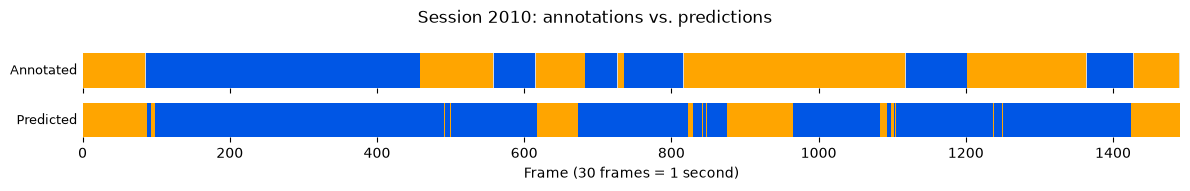

In [9]:
# Why: put annotations and predictions on the same timeline for one
# session, so agreement/disagreement is visible before computing any
# summary numbers.
if not frame_preds:
    print('No predictions loaded - skipping dual ethogram.')
else:
    candidates = [s for s in dense_sessions if s in frame_preds]
    if not candidates:
        candidates = [s for s in session_ids if s in frame_preds]
    focus = candidates[0] if candidates else None

    if focus is None:
        print('No overlapping session found.')
    else:
        ann_arr  = frame_labels[focus]
        pred_arr = frame_preds[focus]
        n = min(len(ann_arr), len(pred_arr))

        ethogram([('Annotated', ann_arr[:n]), ('Predicted', pred_arr[:n])],
                 title=f'Session {focus}: annotations vs. predictions')
        plt.show()

## The Null Model Trap

Before computing classifier metrics, compute what a trivially bad classifier scores.

A **null classifier** always predicts 'not grooming'. On a session where grooming occupies 15% of frames it is correct 85% of the time - high accuracy without detecting the behavior at all.

This is why accuracy alone misleads on imbalanced behavioral data. The metrics that reward actually detecting the behavior are recall and precision, combined as F1.

In [10]:
# Why: establish the null-model baseline accuracy first - without it, the classifier's
# own accuracy number has no context. The counts come from jabs-cli evaluate.
if eval_json is None:
    print('No evaluation results - run the cell that scores the classifier first.')
else:
    fr = eval_json['stages']['raw']['overall']['frames']
    prevalence = (fr['true_positive'] + fr['false_negative']) / fr['evaluated_frames']
    # The baseline is plain arithmetic on those counts: the share of reviewed frames that are not grooming.
    print(f'Grooming prevalence in the dense test session: {100 * prevalence:.1f}% of reviewed frames')
    print(f'Null model accuracy (never predict grooming) : {100 * (1 - prevalence):.1f}%')
    print(f"Classifier accuracy (from jabs-cli evaluate)  : {100 * fr['accuracy']:.1f}%")
    print()
    print('Accuracy alone does not tell you how good a classifier is: a null model scores')
    print('well whenever the behavior is rare. Session 2010 is unusual (grooming is about half')
    print('of its frames, so the baseline is low), but read F1 and recall below either way.')

Grooming prevalence in the dense test session: 52.9% of reviewed frames
Null model accuracy (never predict grooming) : 47.1%
Classifier accuracy (from jabs-cli evaluate)  : 68.1%

Accuracy alone does not tell you how good a classifier is: a null model scores
well whenever the behavior is rare. Session 2010 is unusual (grooming is about half
of its frames, so the baseline is low), but read F1 and recall below either way.


## Classifier Metrics on the Dense Test Session

| Metric | Formula | Asks |
|--------|---------|------|
| Accuracy | (TP + TN) / all | What fraction of all frames did we classify correctly? |
| Recall | TP / (TP + FN) | Of all grooming frames, what fraction did we catch? |
| Precision | TP / (TP + FP) | Of frames we called grooming, what fraction actually were? |
| F1 | 2 * P * R / (P + R) | Harmonic mean of precision and recall |

**When does each matter?**
- **Recall** matters most when missing the behavior has high cost.
- **Precision** matters most when acting on every positive prediction is costly.
- **F1** is the standard summary for imbalanced behavioral data.
- **Accuracy** is meaningful only when classes are balanced - rare in behavior annotation.

Confusion matrix (reviewed frames only):
                    Predicted NOT  Predicted GROOMING
  Actual NOT               691               11
  Actual GROOMING          465              324

  Accuracy      0.681
  Recall        0.411
  Precision     0.967
  F1            0.577


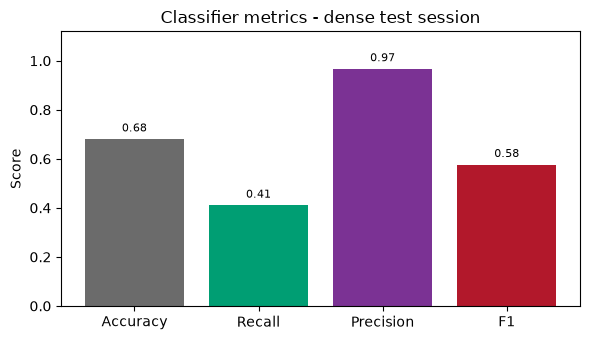

In [11]:
# Why: show the confusion matrix and the metrics exactly as jabs-cli evaluate reported them.
if eval_json is None:
    print('No evaluation results - run the cell that scores the classifier first.')
else:
    fr = eval_json['stages']['raw']['overall']['frames']
    print('Confusion matrix (reviewed frames only):')
    print('                    Predicted NOT  Predicted GROOMING')
    print(f"  Actual NOT           {fr['true_negative']:7d}          {fr['false_positive']:7d}")
    print(f"  Actual GROOMING      {fr['false_negative']:7d}          {fr['true_positive']:7d}")
    print()

    metrics = {'Accuracy': fr['accuracy'], 'Recall': fr['recall_behavior'],
               'Precision': fr['precision_behavior'], 'F1': fr['f1_behavior']}
    for name, val in metrics.items():
        print(f'  {name:12s}  {val:.3f}')

    fig, ax = plt.subplots(figsize=(6, 3.5))
    metric_bars(ax, {'Raw': metrics}, title='Classifier metrics - dense test session')
    plt.tight_layout()
    plt.show()

## Behavior Meets Pose: Does Movement Match the Labels?

During grooming, mice stop locomoting and make repetitive paw-to-face movements. The center-spine keypoint should show **low frame-to-frame displacement** during labeled grooming frames compared to non-grooming frames.

This is an independent check: if the kinematic signal does not separate the two classes, the labels may not be capturing a real behavioral state.


Sessions used: 7
Grooming  frames:   4894  mean disp: 0.65 px/frame
Other     frames:   9523  mean disp: 0.44 px/frame


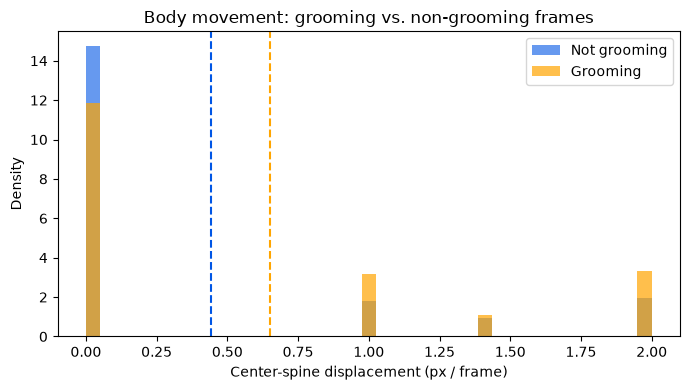

In [12]:
# Why: independently check that grooming labels correspond to a real
# behavioral signal (reduced movement), not just annotator noise.
CENTER_SPINE = KEYPOINT_NAMES.index("center_spine") if "center_spine" in KEYPOINT_NAMES else 6

groom_speeds, other_speeds = [], []
sessions_used = 0

for pose_path in pose_files:
    sid = pose_path.stem.split('_pose_est')[0]
    lab = frame_labels.get(sid)
    if lab is None or (lab == 1).sum() < 10:
        continue
    with h5py.File(str(pose_path), 'r') as f:
        pts = f['poseest/points'][:, 0, CENTER_SPINE, :].astype(float)
    # disp[i] is the displacement from frame i to frame i+1, so it aligns
    # with the label of the frame the mouse moved *into* - hence lab[1:].
    disp  = np.linalg.norm(pts[1:] - pts[:-1], axis=1)
    lab_s = lab[1:]
    groom_speeds.extend(disp[lab_s == 1].tolist())
    other_speeds.extend(disp[lab_s == 0].tolist())
    sessions_used += 1

if not groom_speeds:
    print('Not enough grooming frames to compare.')
else:
    print(f'Sessions used: {sessions_used}')
    print(f'Grooming  frames: {len(groom_speeds):6d}  mean disp: {np.mean(groom_speeds):.2f} px/frame')
    print(f'Other     frames: {len(other_speeds):6d}  mean disp: {np.mean(other_speeds):.2f} px/frame')

    cap  = float(np.percentile(other_speeds, 95))
    bins = np.linspace(0, cap, 40)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(np.clip(other_speeds, 0, cap), bins=bins, alpha=0.6,
            color=NOT_BEHAVIOR_COLOR, label='Not grooming', density=True)
    ax.hist(np.clip(groom_speeds, 0, cap), bins=bins, alpha=0.7,
            color=BEHAVIOR_COLOR, label='Grooming', density=True)
    ax.axvline(np.mean(groom_speeds), color=BEHAVIOR_COLOR, linestyle='--', linewidth=1.5)
    ax.axvline(np.mean(other_speeds), color=NOT_BEHAVIOR_COLOR, linestyle='--', linewidth=1.5)
    ax.set_xlabel('Center-spine displacement (px / frame)')
    ax.set_ylabel('Density')
    ax.set_title('Body movement: grooming vs. non-grooming frames')
    ax.legend()
    plt.tight_layout()
    plt.show()

## Understanding Checkpoint

1. The coverage table showed some sessions with less than 100% of frames reviewed. If you included one of those sessions in the dense test set and computed F1, how would the missing labels affect the result, and in which direction?

2. The null model gets high accuracy on imbalanced data. Why does F1 correctly score it at or near 0? Walk through the precision and recall of a classifier that always predicts not-grooming.

3. You run the active learning loop for several rounds and LOOCV F1 plateaus at 0.72. You open the dense test set and get test F1 = 0.61. What are two plausible explanations for the gap?

4. A collaborator suggests splitting randomly at the frame level to get a larger test set. What would go wrong with the F1 estimate, and why?


## Challenge Questions

- Annotate the same 30-second clip independently with a partner. What fraction of frames do you agree on? How does inter-annotator disagreement set a ceiling on classifier F1?
- Compute a second pose feature during grooming (e.g., nose-to-center-spine distance). Does it separate grooming from non-grooming? Do the two features carry the same information?
- Inspect the session with the lowest per-session F1. Does it have fewer annotations, unusual grooming prevalence, or lower coverage? What does that suggest?


## What's Next

You have completed the full JABS workflow: loading and quality-checking pose data, annotating a behavior, training a classifier with LOOCV, and evaluating it against dense ground truth on a held-out test set.

Natural extensions:

- **Scale:** apply the classifier to the full Harvard Dataverse dataset for cross-strain behavioral comparison.
- **Multi-behavior:** extend the annotation project with additional behaviors (rearing, social interaction) to build a behavioral fingerprint.
- **Inter-annotator reliability:** have two annotators label the same sessions and compute Cohen's kappa - this sets an upper bound on classifier performance.
- **Feature importance:** examine XGBoost feature importances to understand which kinematic features drive grooming classification.
